In [1]:
!pip -q install numpy tensorflow keras

**Loading the dataset**

In [2]:
from keras.utils import to_categorical

In [3]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


**Exploratory Analysis**

This section focuses on the visualization of some handwritten digits and the distribution of each label (from 0 to 9) in the training dataset

In [4]:
import matplotlib.pyplot as plt
import random

In [5]:
print("Training Data")
print("Number of images: ", len(train_images))
print("Number of labels: ", len(train_labels))
print(f"- X = {train_images.shape}, y = {train_labels.shape}")
print(f"- Hols {train_images.shape[0]/70000* 100}% of the overall data")

print("\n")

print("Testing data")
print(f"- X = {test_images.shape}, y = {test_labels.shape}")
print(f"- Hols {test_images.shape[0]/70000* 100}% of the overall data")

Training Data
Number of images:  60000
Number of labels:  60000
- X = (60000, 28, 28), y = (60000,)
- Hols 85.71428571428571% of the overall data


Testing data
- X = (10000, 28, 28), y = (10000,)
- Hols 14.285714285714285% of the overall data


**Random Digits from training dataset**

In [6]:
def plot_images(images_to_plot, train_data):
  #Generate a list of random data from training set
  random_indices = random.sample(range(len(train_data)), images_to_plot)

  #plot each image using random indicies
  for i, idx in enumerate(random_indices):
     plt.subplot(3, 3, i + 1)
     plt.imshow(train_data[idx], cmap=plt.get_cmap('gray'))

  plt.show()

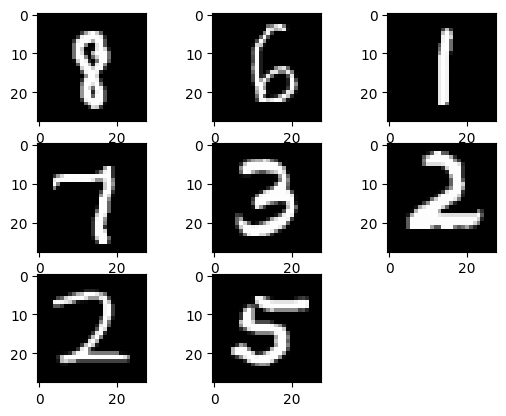

In [7]:
images_to_plot = 8
plot_images(images_to_plot,train_images)

**Digits Distrubution**

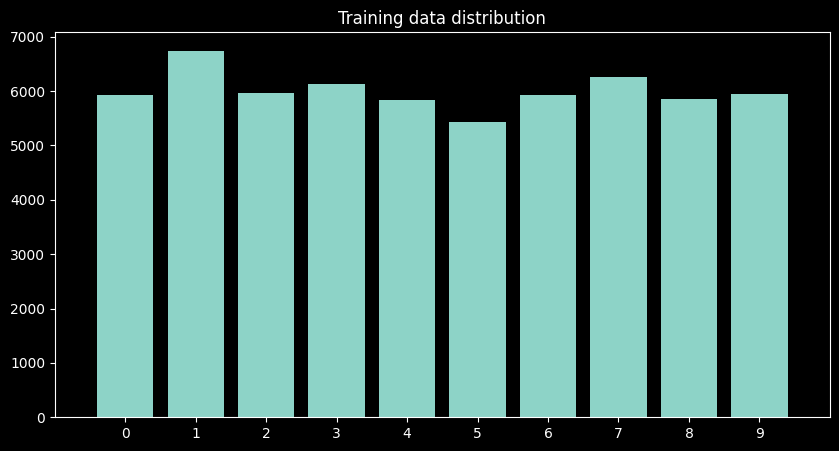

In [8]:
import numpy as np

def plot_labels_distrubution(labels):

  counts = np.bincount(labels)

  plt.style.use('dark_background')

  fig, ax = plt.subplots(figsize=(10,5))
  ax.bar(range(10), counts, width=0.8, align='center')
  ax.set(xticks=range(10), xlim=[-1, 10], title='Training data distribution')

  plt.show()

plot_labels_distrubution(train_labels)

**Preprocessing**

In [9]:
from keras.utils import to_categorical

In [10]:
def preprocess_data(data,label,grayscale_size,vector_size):
  #converted to one dimensional vector
   preprocessed_images = np.reshape(data, [-1, vector_size])
   preprocessed_images = preprocessed_images.astype('float32') / grayscale_size

   encoded_labels = to_categorical(label)
   return preprocessed_images, encoded_labels

In [11]:
vector_size = 28*28
grayscale_size = 255
train_size = train_images.shape[0]
test_size = test_images.shape[0]

# preprocessing of the training data
train_images, train_labels = preprocess_data(train_images, train_labels, grayscale_size, vector_size)

# preprocessing of the testing data
test_images, test_labels = preprocess_data(test_images, test_labels, grayscale_size, vector_size)

In [12]:
#check normalization
print("Training data")
print(f"- Maxium Value {train_images.max()} ")
print(f"- Minimum Value {train_images.min()} ")

print("\n")

print("Testing data")
print(f"- Maxium Value {test_images.max()} ")
print(f"- Minimum Value {test_images.min()} ")

Training data
- Maxium Value 1.0 
- Minimum Value 0.0 


Testing data
- Maxium Value 1.0 
- Minimum Value 0.0 


In [13]:
test_images

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [14]:
test_labels

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

**Building the Neural Network**

In [15]:
from keras import models
from keras import layers
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dense
from keras.layers import Dense, Activation, Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import BatchNormalization

In [16]:
hidden_units = 256
dropout = 0.5
nb_unique_labels = 10
vector_size = 784

def network_architecture():

  network = models.Sequential()
  #input layer
  network.add(Dense(vector_size,activation="relu",input_shape = (vector_size,)))
  #hidden layer
  network.add(Dense(512, activation='relu'))
  network.add(Dense(nb_unique_labels, activation='softmax'))


  return network

In [17]:
network = network_architecture()
network

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


<Sequential name=sequential, built=True>

In [18]:
network.compile(optimizer='rmsprop',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

In [19]:
network

<Sequential name=sequential, built=True>

In [20]:
from keras.callbacks import EarlyStopping

In [21]:
# Fit the model
batch_size = 256
n_epochs = 15
val_split = 0.1

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

# Fit the model with the callback
history = network.fit(train_images, train_labels, validation_split=val_split,
            epochs=n_epochs, batch_size=batch_size, callbacks=[early_stopping])

Epoch 1/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.9066 - loss: 0.2993 - val_accuracy: 0.9730 - val_loss: 0.0941
Epoch 2/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.9679 - loss: 0.1022 - val_accuracy: 0.9755 - val_loss: 0.0809
Epoch 3/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.9798 - loss: 0.0639 - val_accuracy: 0.9755 - val_loss: 0.0798
Epoch 4/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9862 - loss: 0.0437 - val_accuracy: 0.9788 - val_loss: 0.0741
Epoch 5/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.9907 - loss: 0.0298 - val_accuracy: 0.9802 - val_loss: 0.0680
Epoch 6/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.9930 - loss: 0.0214 - val_accuracy: 0.9813 - val_loss: 0.0670
Epoch 7/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9948 - loss: 0.0162 - val_accuracy: 0.9810 - val_loss: 0.0814
Epoch 8/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9963 - loss: 0.0120 - val_a

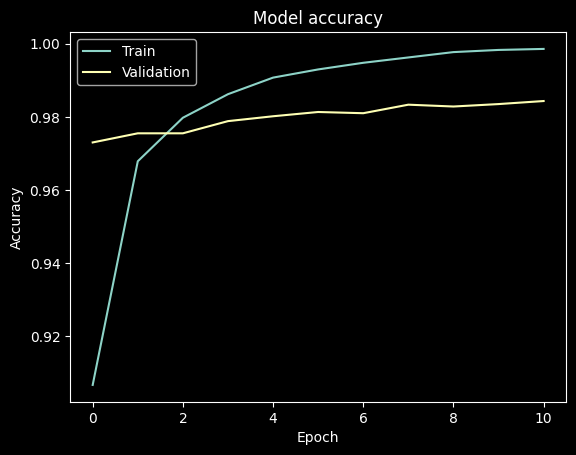

In [22]:
# plot the training history
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [23]:
loss, acc = network.evaluate(test_images,
                             test_labels, batch_size=batch_size)

print("\nTest accuracy: %.1f%%" % (100.0 * acc))

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9835 - loss: 0.0708

Test accuracy: 98.4%


In [24]:
import numpy as np

predictions = network.predict(test_images)

predicted_labels = np.argmax(predictions, axis=1)
true_labels = np.argmax(test_labels, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


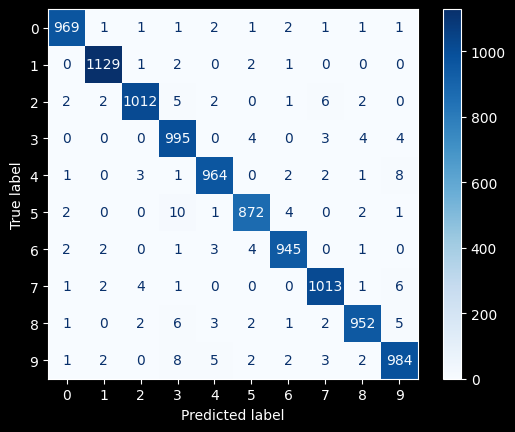

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues")
plt.show()

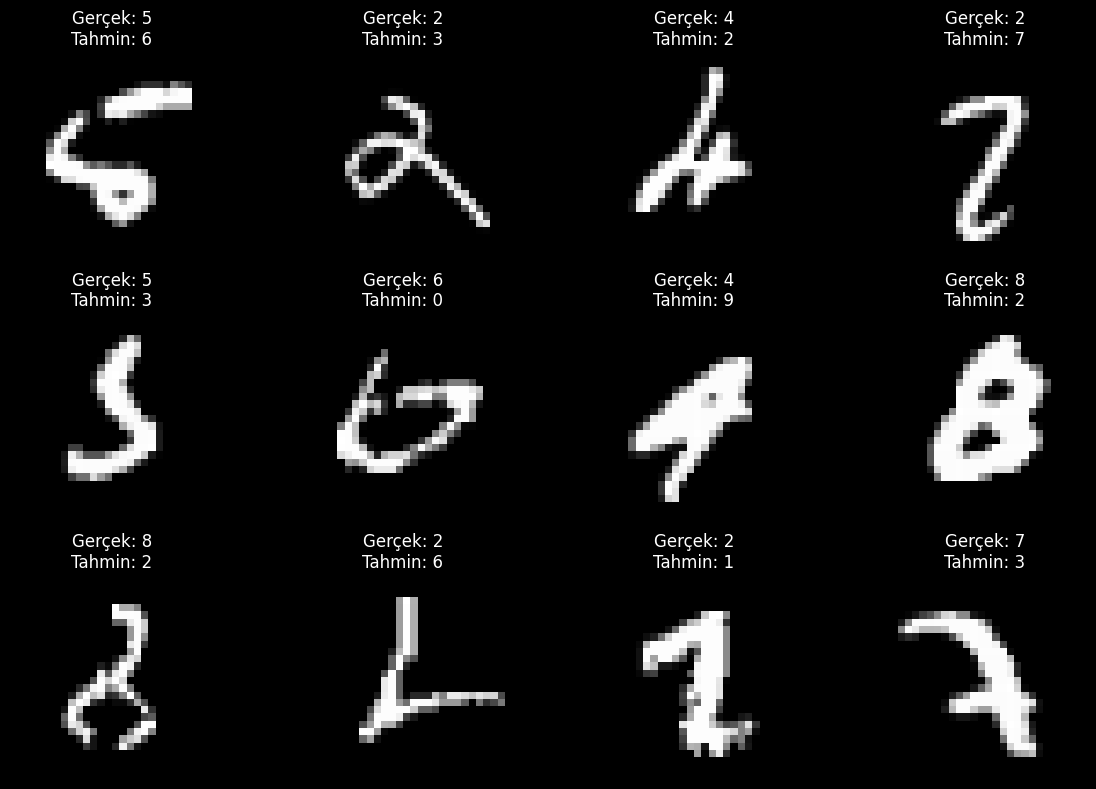

In [26]:
wrong_indices = np.where(predicted_labels != true_labels)[0]

plt.figure(figsize=(12, 8))

for i, index in enumerate(wrong_indices[:12]):
    plt.subplot(3, 4, i + 1)

    plt.imshow(
        test_images[index].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Gerçek: {true_labels[index]}\n"
        f"Tahmin: {predicted_labels[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()